In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from datetime import datetime

# Charger les données
data = pd.read_csv('segment_alerts_all_airports_train.csv')

# Afficher les informations de base
print("=" * 50)
print("INFORMATIONS SUR LE DATASET")
print("=" * 50)
print(f"Nombre de lignes: {len(data)}")
print(f"Nombre de colonnes: {len(data.columns)}")
print("\nColonnes disponibles:")
print(data.columns.tolist())
print("\nPremières lignes:")
data.head()

INFORMATIONS SUR LE DATASET
Nombre de lignes: 507071
Nombre de colonnes: 13

Colonnes disponibles:
['lightning_id', 'lightning_airport_id', 'date', 'lon', 'lat', 'amplitude', 'maxis', 'icloud', 'dist', 'azimuth', 'airport', 'airport_alert_id', 'is_last_lightning_cloud_ground']

Premières lignes:


,lightning_id,lightning_airport_id,date,lon,lat,amplitude,maxis,icloud,dist,azimuth,airport,airport_alert_id,is_last_lightning_cloud_ground
0,1,1,2016-01-02 14:53:36+00:00,9.0559,42.0826,-9.90,0.3,False,27.360653,57.852343,Ajaccio,NaN,NaN
1,2,2,2016-01-02 14:53:36+00:00,9.0236,42.0953,-3.33,0.2,True,26.383167,52.117828,Ajaccio,NaN,NaN
2,3,3,2016-01-02 21:22:53+00:00,8.8585,42.0456,-18.68,0.4,True,14.313391,24.500543,Ajaccio,NaN,NaN
3,4,4,2016-01-02 21:22:53+00:00,8.8517,42.0517,-7.51,0.2,False,14.794117,20.854458,Ajaccio,1.0,False
4,5,5,2016-01-02 21:24:46+00:00,8.8728,42.0494,-6.01,0.2,False,15.124224,29.058471,Ajaccio,1.0,False


/tmp/ipykernel_356778/1815967234.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=airport_counts.index, y=airport_counts.values, palette='viridis')


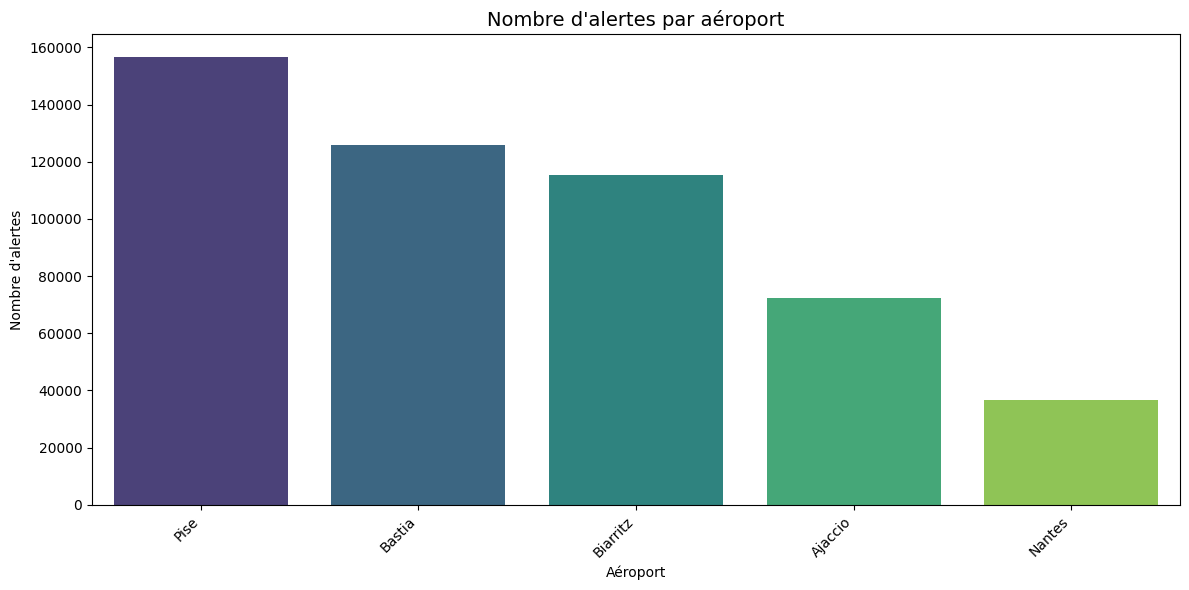

In [2]:
# 1. Visualisation de la distribution des aéroports
plt.figure(figsize=(12, 6))
airport_counts = data['airport'].value_counts()
sns.barplot(x=airport_counts.index, y=airport_counts.values, palette='viridis')
plt.title('Nombre d\'alertes par aéroport', fontsize=14)
plt.xlabel('Aéroport')
plt.ylabel('Nombre d\'alertes')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

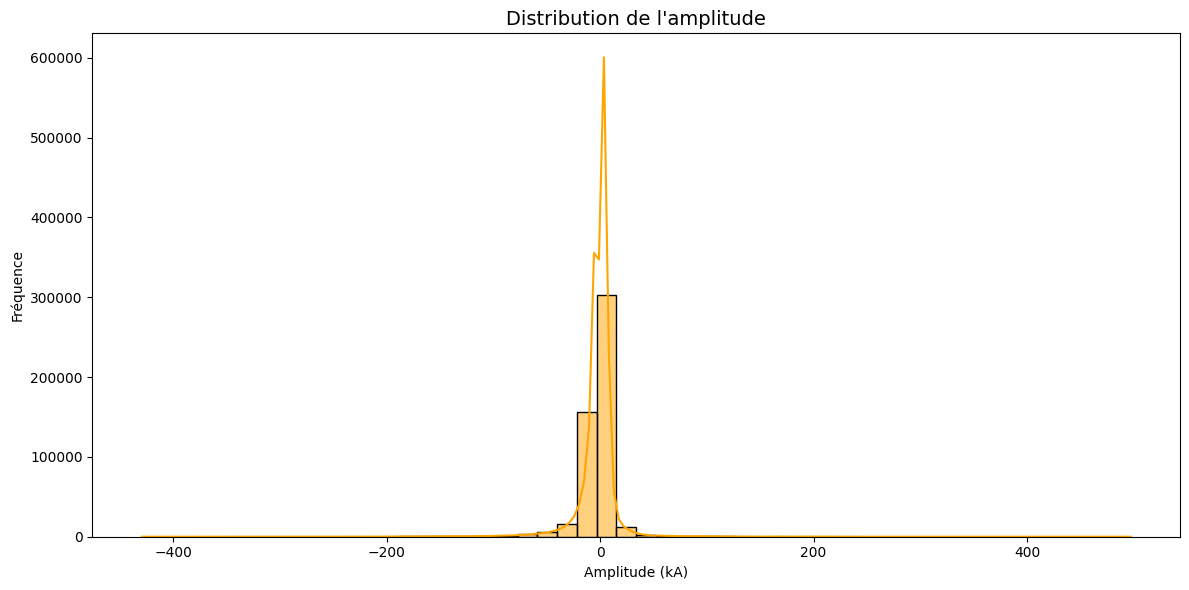

In [12]:
# 2. Distribution des amplitudes
plt.figure(figsize=(12, 6))
sns.histplot(data['amplitude'], bins=50, kde=True, color='orange')
plt.title('Distribution de l\'amplitude', fontsize=14)
plt.xlabel('Amplitude (kA)')
plt.ylabel('Fréquence')
plt.tight_layout()
plt.show()

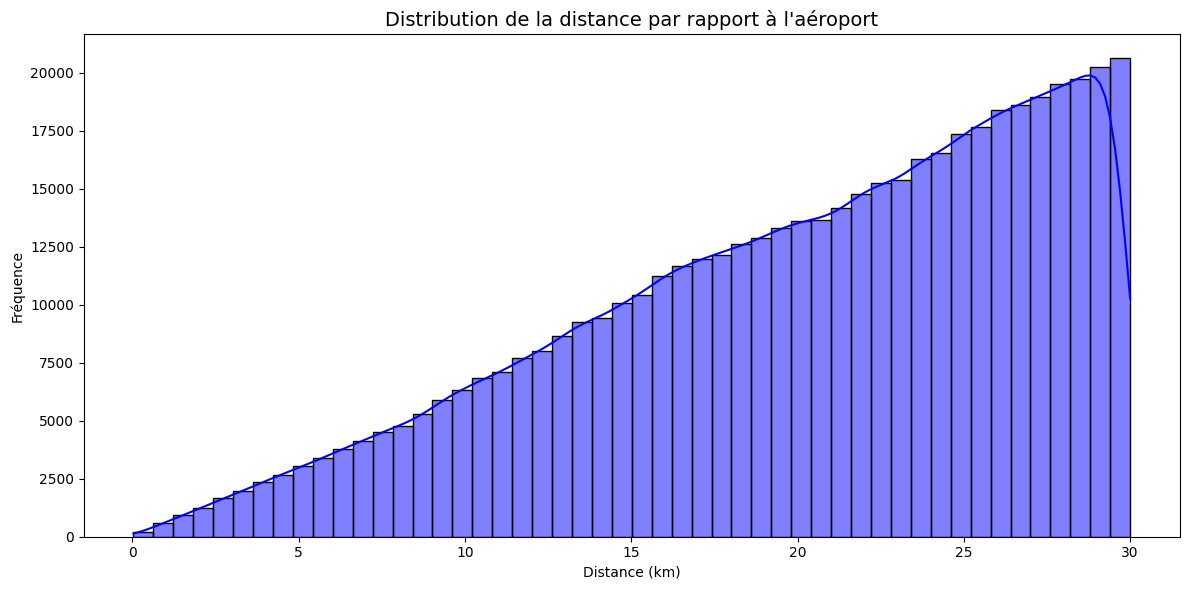

In [4]:
# 3. Distribution des distances
plt.figure(figsize=(12, 6))
sns.histplot(data['dist'], bins=50, kde=True, color='blue')
plt.title('Distribution de la distance par rapport à l\'aéroport', fontsize=14)
plt.xlabel('Distance (km)')
plt.ylabel('Fréquence')
plt.tight_layout()
plt.show()

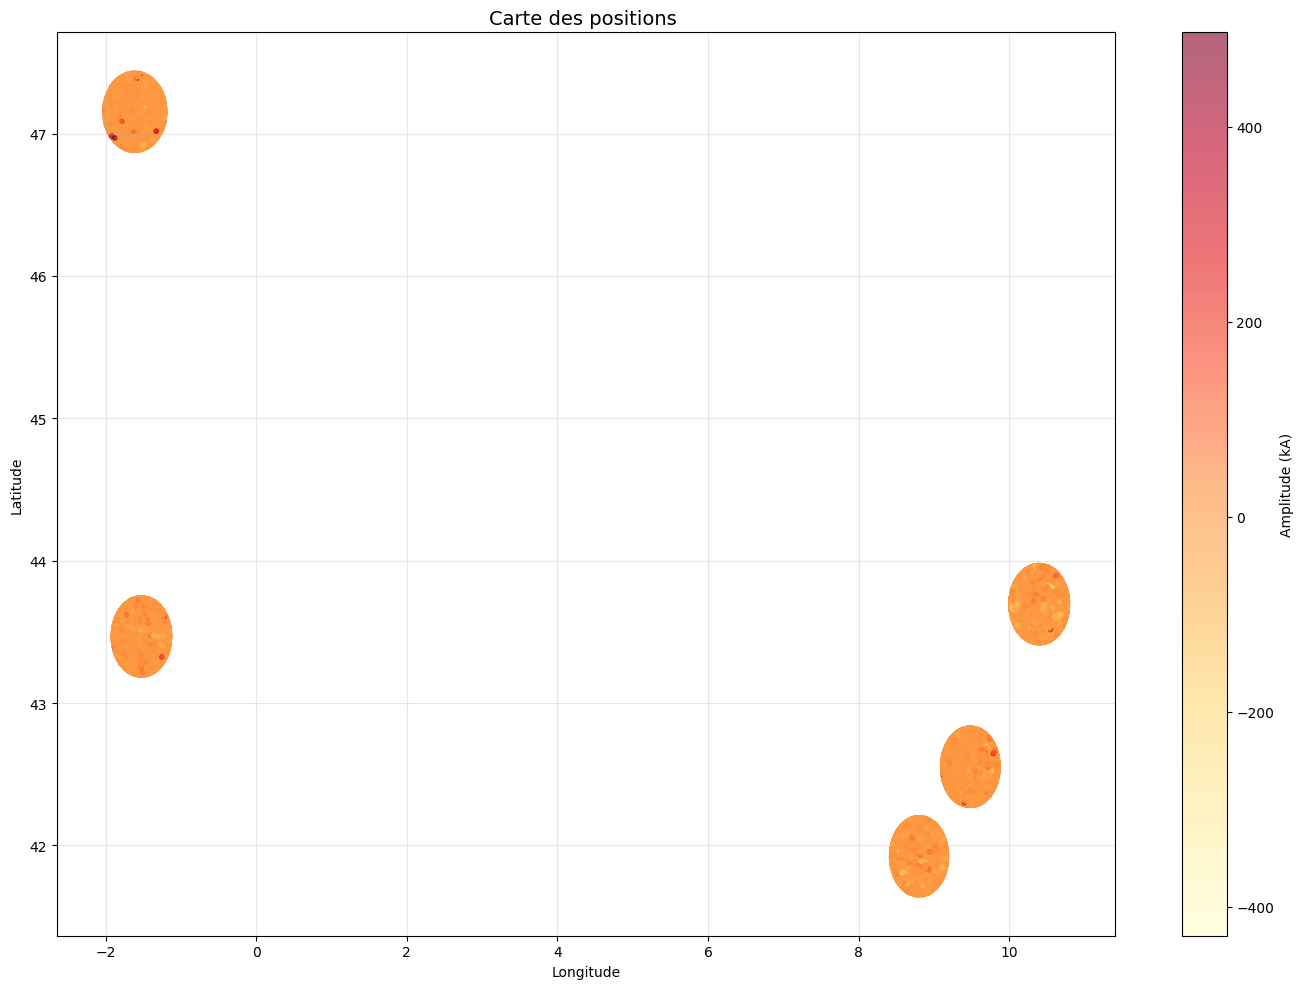

In [13]:
# 4. Carte des positions  (scatter plot)
plt.figure(figsize=(14, 10))
scatter = plt.scatter(data['lon'], data['lat'], c=data['amplitude'], 
                      cmap='YlOrRd', alpha=0.6, s=10)
plt.colorbar(scatter, label='Amplitude (kA)')
plt.title('Carte des positions ', fontsize=14)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

/tmp/ipykernel_356778/4189539507.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=monthly_counts.index, y=monthly_counts.values, palette='coolwarm')


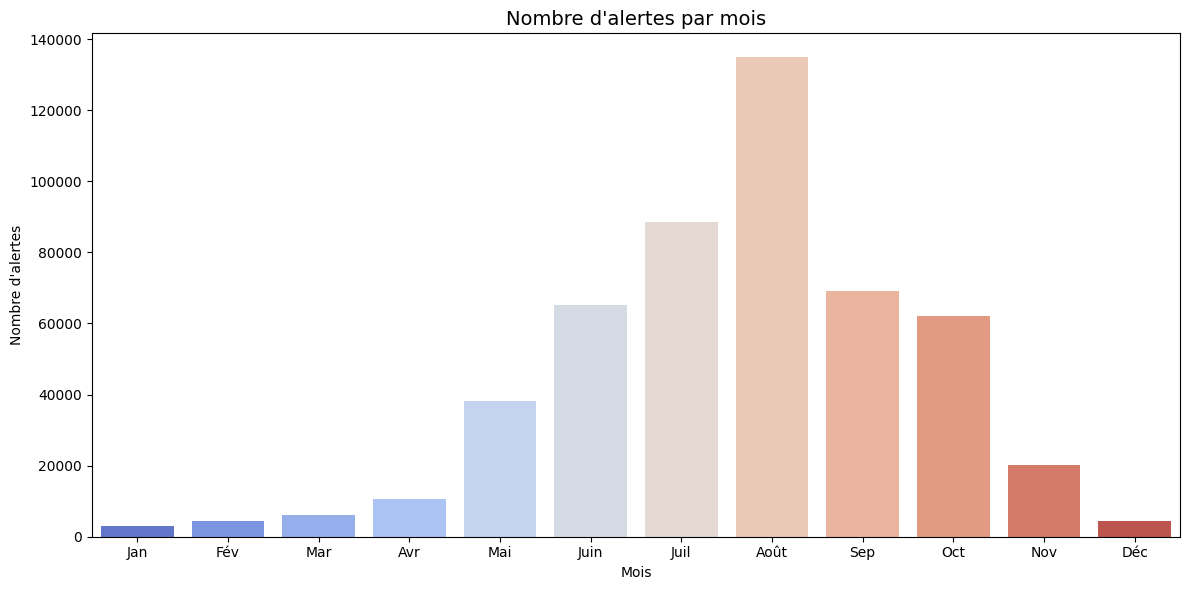

In [6]:
# 5. Nombre d'alertes par mois
data['date'] = pd.to_datetime(data['date'])
data['month'] = data['date'].dt.month
data['year'] = data['date'].dt.year

plt.figure(figsize=(12, 6))
monthly_counts = data.groupby('month').size()
sns.barplot(x=monthly_counts.index, y=monthly_counts.values, palette='coolwarm')
plt.title('Nombre d\'alertes par mois', fontsize=14)
plt.xlabel('Mois')
plt.ylabel('Nombre d\'alertes')
plt.xticks(range(12), ['Jan', 'Fév', 'Mar', 'Avr', 'Mai', 'Juin', 
                       'Juil', 'Août', 'Sep', 'Oct', 'Nov', 'Déc'])
plt.tight_layout()
plt.show()

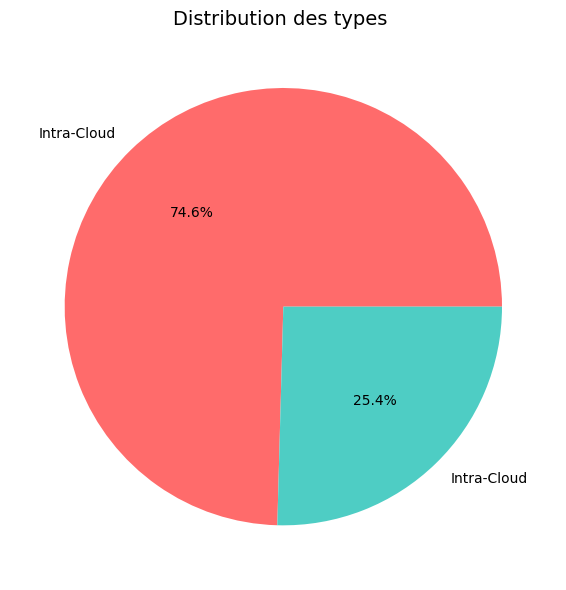

In [14]:
# 6. Distribution de la variable icloud (nuage vs sol)
plt.figure(figsize=(8, 6))
icloud_counts = data['icloud'].value_counts()
plt.pie(icloud_counts.values, labels=['Cloud-to-Ground' if not icloud_counts.index[0] else 'Intra-Cloud', 
                               'Intra-Cloud' if icloud_counts.index[0] else 'Cloud-to-Ground'],
        autopct='%1.1f%%', colors=['#ff6b6b', '#4ecdc4'])
plt.title('Distribution des types ', fontsize=14)
plt.tight_layout()
plt.show()

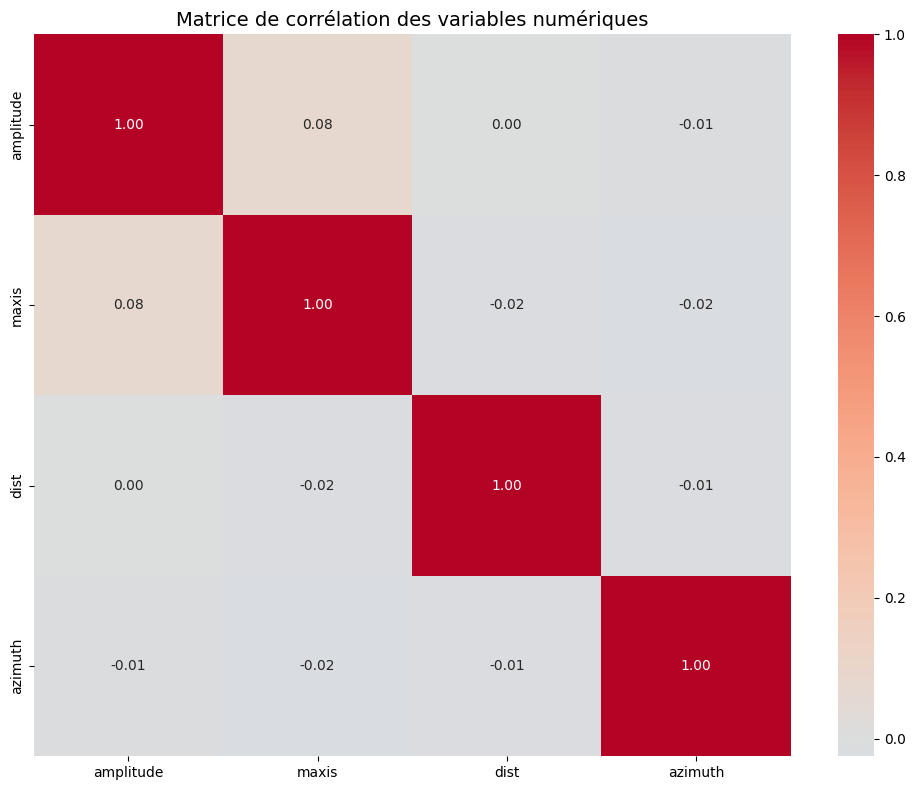

In [8]:
# 7. Matrice de corrélation
plt.figure(figsize=(10, 8))
numeric_cols = ['amplitude', 'maxis', 'dist', 'azimuth']
corr_matrix = data[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Matrice de corrélation des variables numériques', fontsize=14)
plt.tight_layout()
plt.show()

/tmp/ipykernel_356778/2906773073.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=yearly_counts.index, y=yearly_counts.values, palette='Set2')


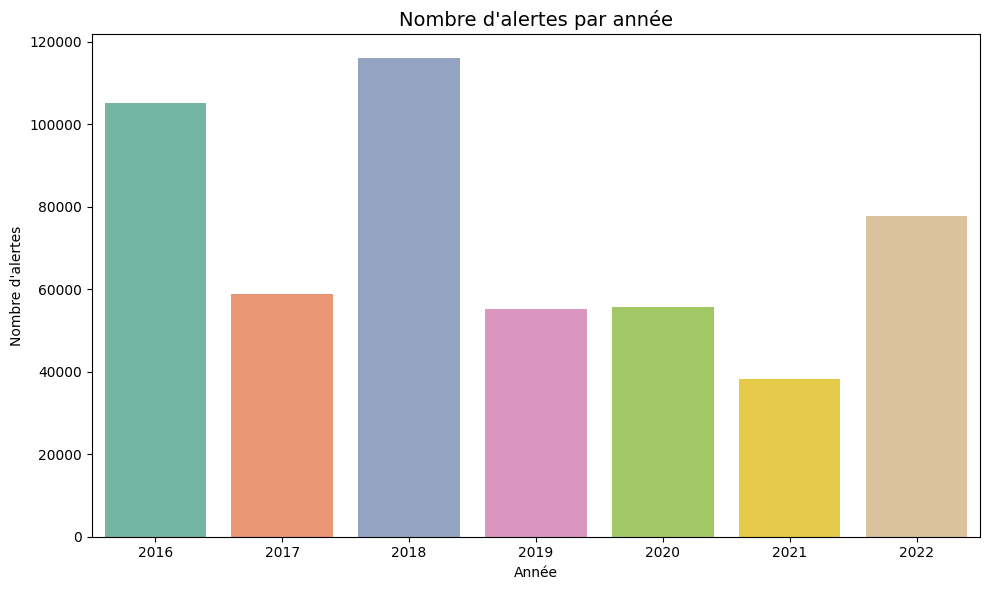

In [9]:
# 8. Alertes par année
plt.figure(figsize=(10, 6))
yearly_counts = data.groupby('year').size()
sns.barplot(x=yearly_counts.index, y=yearly_counts.values, palette='Set2')
plt.title('Nombre d\'alertes par année', fontsize=14)
plt.xlabel('Année')
plt.ylabel('Nombre d\'alertes')
plt.tight_layout()
plt.show()

/tmp/ipykernel_356778/388658767.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='airport', y='amplitude', data=data, palette='Set3')


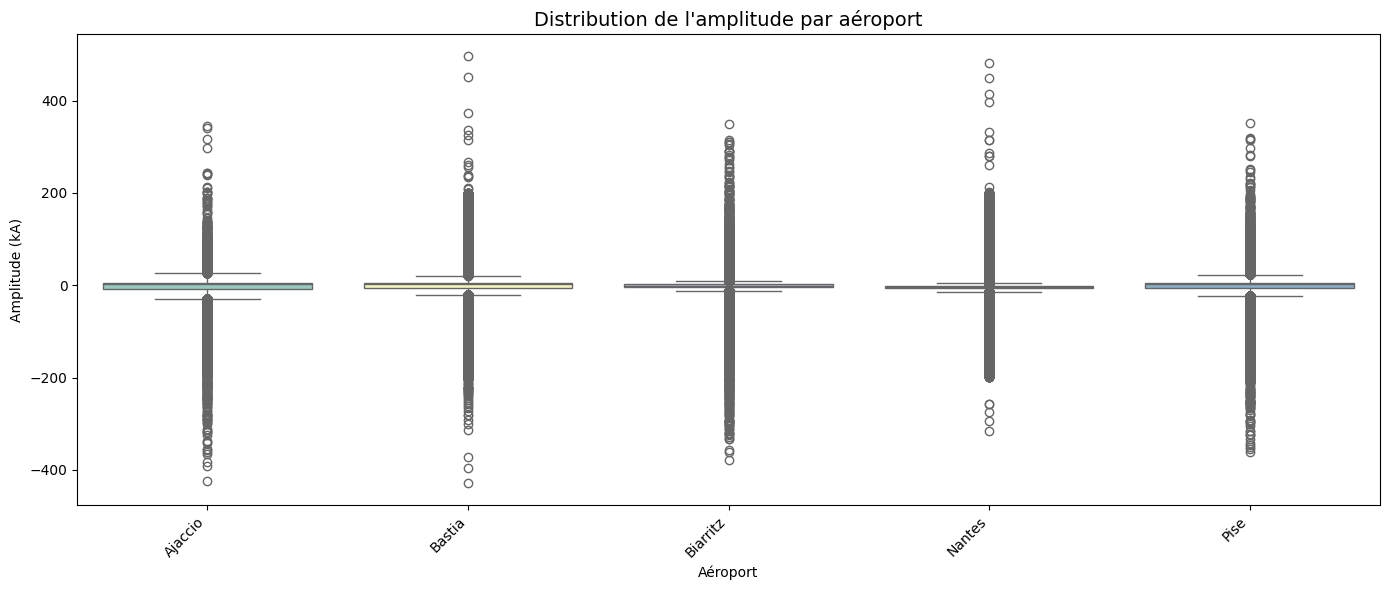

In [10]:
# 9. Boxplot de l'amplitude par aéroport
plt.figure(figsize=(14, 6))
sns.boxplot(x='airport', y='amplitude', data=data, palette='Set3')
plt.title('Distribution de l\'amplitude par aéroport', fontsize=14)
plt.xlabel('Aéroport')
plt.ylabel('Amplitude (kA)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [11]:
# 10. Statistiques résumées
print("=" * 50)
print("STATISTIQUES RÉSUMÉES")
print("=" * 50)
print("\nStatistiques descriptives:")
print(data[['amplitude', 'maxis', 'dist', 'azimuth']].describe())

print("\n\nNombre d'alertes par aéroport:")
print(data['airport'].value_counts())

print("\n\nTypes de молнии (icloud):")
print(data['icloud'].value_counts())

STATISTIQUES RÉSUMÉES

Statistiques descriptives:
           amplitude          maxis           dist        azimuth
count  507071.000000  507071.000000  507071.000000  507071.000000
mean       -2.254868       1.025518      20.243757     168.806028
std        20.252913       1.359688       6.941580      97.587294
min      -429.500000       0.016000       0.037212       0.000000
25%        -5.610000       0.107000      15.412370      85.240722
50%        -1.560000       0.245000      21.442300     156.717299
75%         4.620000       1.538000      26.112228     251.482192
max       497.000000       6.900000      29.999996     359.978549


Nombre d'alertes par aéroport:
airport
Pise        156718
Bastia      125919
Biarritz    115191
Ajaccio      72501
Nantes       36742
Name: count, dtype: int64


Types de молнии (icloud):
icloud
True     378079
False    128992
Name: count, dtype: int64
